In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [45]:
import pandas as pd

ROOT = Path.home() / "code/MBS_thesis"

layers = (
    pd.read_csv(ROOT / "stacr_layers.csv", parse_dates = ['closing_date'],
                dtype={"deal_id": "string", "layer": "string",
                       "retained_slice": "string", "index": "category"})
      .rename(columns={"pool": "pool_upb"})          # "pool" is the cut-off pool balance in $
)

# 2019FTR3-A -> year 2019, shelf FTR, seq 3, sub_pool A
parts = layers["deal_id"].str.extract(r"(?P<year>\d{4})(?P<shelf>[A-Z]+)(?P<seq>\d+)(?:-(?P<sub_pool>[A-D]))?")
layers = layers.join(parts.astype({"year": "Int16", "seq": "Int8"}))

# float dust: attach of the bottom layer can come out as -1e-17
layers[["attach", "detach"]] = layers[["attach", "detach"]].clip(lower=0).round(8)
layers["thickness"] = layers["detach"] - layers["attach"]

layers = layers.sort_values(["closing_date", "deal_id", "rank"]).reset_index(drop=True)

In [46]:
layers.head(10)

,deal_id,closing_date,layer,retained_slice,notional,stated_attach,rank,detach,attach,sold_balance,index,margin,sold_share,pool_upb,year,shelf,seq,sub_pool,thickness
0,2015HQA1,2015-09-28,A-H,<NA>,1.822399e+10,0.0595,1,1.0000,0.0595,0.0,NaN,NaN,0.000000,1.937691e+10,2015,HQA,1,<NA>,0.9405
1,2015HQA1,2015-09-28,M-1,M-1H,1.937691e+08,0.0495,2,0.0595,0.0495,160000000.0,One-Month LIBOR,0.0125,0.825725,1.937691e+10,2015,HQA,1,<NA>,0.0100
2,2015HQA1,2015-09-28,M-2,M-2H,4.359805e+08,0.0270,3,0.0495,0.0270,360000000.0,One-Month LIBOR,0.0265,0.825725,1.937691e+10,2015,HQA,1,<NA>,0.0225
3,2015HQA1,2015-09-28,M-3,M-3H,3.294075e+08,0.0100,4,0.0270,0.0100,272000000.0,One-Month LIBOR,0.0470,0.825725,1.937691e+10,2015,HQA,1,<NA>,0.0170
4,2015HQA1,2015-09-28,B,B-H,1.937691e+08,0.0000,5,0.0100,0.0000,80000000.0,One-Month LIBOR,0.0880,0.412862,1.937691e+10,2015,HQA,1,<NA>,0.0100
5,2015DNA3,2015-11-09,A-H,<NA>,3.267595e+10,0.0585,1,1.0000,0.0585,0.0,NaN,NaN,0.000000,3.470626e+10,2015,DNA,3,<NA>,0.9415
6,2015DNA3,2015-11-09,M-1,M-1H,3.470626e+08,0.0485,2,0.0585,0.0485,200000000.0,One-Month LIBOR,0.0135,0.576265,3.470626e+10,2015,DNA,3,<NA>,0.0100
7,2015DNA3,2015-11-09,M-2,M-2H,7.635378e+08,0.0265,3,0.0485,0.0265,440000000.0,One-Month LIBOR,0.0285,0.576265,3.470626e+10,2015,DNA,3,<NA>,0.0220
8,2015DNA3,2015-11-09,M-3,M-3H,5.726533e+08,0.0100,4,0.0265,0.0100,330000000.0,One-Month LIBOR,0.0470,0.576265,3.470626e+10,2015,DNA,3,<NA>,0.0165
9,2015DNA3,2015-11-09,B,B-H,3.470626e+08,0.0000,5,0.0100,0.0000,100000000.0,One-Month LIBOR,0.0935,0.288132,3.470626e+10,2015,DNA,3,<NA>,0.0100


In [56]:
deals = layers.groupby("deal_id").agg(
    closing_date = ("closing_date", "first"), shelf=("shelf", "first"), pool_upb=("pool_upb", "first"),
    n_layers=("layer", "size"), senior_ce=("attach", "max"),
    sold=("sold_balance", "sum"))
deals["sold_pct_of_pool"] = deals["sold"] / deals["pool_upb"]

attach_grid = layers.pivot(index="deal_id", columns="layer", values="attach")  # deal x layer

In [59]:
deals

,closing_date,shelf,pool_upb,n_layers,senior_ce,sold,sold_pct_of_pool
deal_id,,,,,,,
2015DNA3,2015-11-09,DNA,3.470626e+10,5,0.0585,1.070000e+09,0.030830
2015HQA1,2015-09-28,HQA,1.937691e+10,5,0.0595,8.720000e+08,0.045002
2015HQA2,2015-12-08,HQA,1.710346e+10,5,0.0640,5.900000e+08,0.034496
2016DNA1,2016-01-21,DNA,3.572406e+10,5,0.0500,9.960000e+08,0.027880
2016DNA2,2016-05-10,DNA,3.012095e+10,6,0.0500,9.160000e+08,0.030411
...,...,...,...,...,...,...,...
2024DNA1,2024-02-09,DNA,1.828023e+10,8,0.0550,5.720000e+08,0.031291
2024DNA2,2024-05-21,DNA,3.208087e+10,8,0.0550,1.005000e+09,0.031327
2024DNA3,2024-10-16,DNA,2.462408e+10,8,0.0500,6.425000e+08,0.026092


<Axes: xlabel='deal_id'>

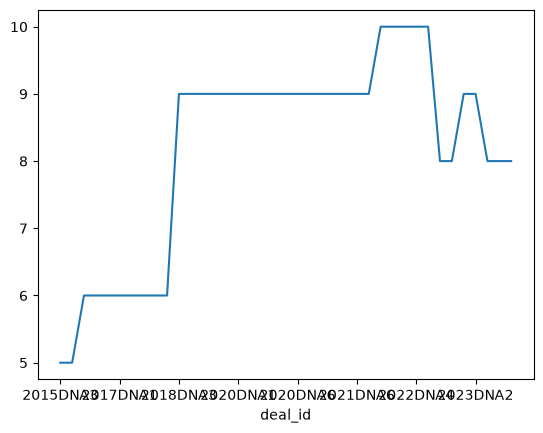

In [61]:
deals[deals['shelf'] == 'DNA']['n_layers'].plot()

<Axes: xlabel='deal_id'>

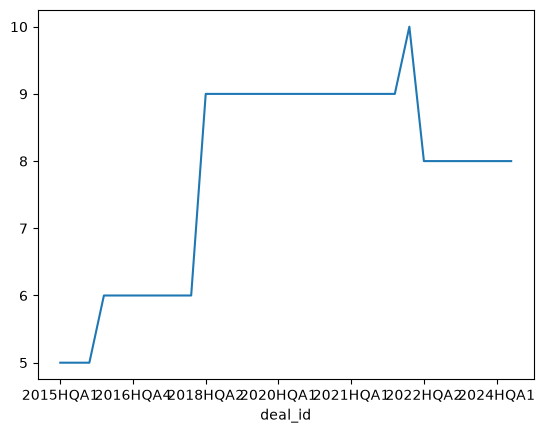

In [62]:
deals[deals['shelf'] == 'HQA']['n_layers'].plot()

<Axes: xlabel='deal_id'>

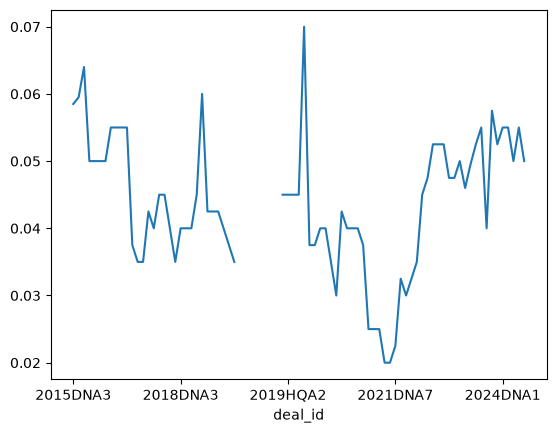

In [53]:
attach_grid['A-H'].plot()

In [54]:
attach_grid

layer,A-1,A-H,A-HA,A-HB,A-HC,A-HD,B,B-1,B-1A,B-1B,...,M-2A,M-2B,M-3,M-3A,M-3B,MB-H,MB-HA,MB-HB,MB-HC,MB-HD
deal_id,,,,,,,,,,,,,,,,,,,,,
2015DNA3,NaN,0.0585,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,...,NaN,NaN,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015HQA1,NaN,0.0595,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,...,NaN,NaN,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015HQA2,NaN,0.0640,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,...,NaN,NaN,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016DNA1,NaN,0.0500,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,...,NaN,NaN,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016DNA2,NaN,0.0500,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,0.02125,0.01,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024DNA1,0.042501,0.0550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.025500,0.0220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024DNA2,0.040001,0.0550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.023501,0.0220,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024DNA3,0.040000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.025250,0.0225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
